In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
print('Virtual environment is ready')
print('Pandas version: ',pd.__version__)
print('Numpy version: ', np.__version__)

Virtual environment is ready
Pandas version:  3.1.0
Numpy version:  2.5.4


In [7]:
file_path = "../data/raw/household_power_consumption.txt"
df = pd.read_csv(file_path, sep=";", na_values=["?"], low_memory=False)
print('Dataset loaded successfully')

Dataset loaded successfully


In [8]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [9]:
df.columns

Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')

In [10]:
df.shape

(2075259, 9)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 176.0 MB


In [13]:
df.isnull().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

## Data Cleaning

In [14]:
data = df.copy()

In [17]:
data["datetime"] = pd.to_datetime(
    data["Date"] + " " + data["Time"],
    format="%d/%m/%Y %H:%M:%S"
)
data.drop(columns=["Date", "Time"], inplace=True)
data.set_index("datetime", inplace=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_20584\2990029746.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(columns=["Date", "Time"], inplace=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_20584\2990029746.py:6: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.set_index("datetime", inplace=True)


In [18]:
data.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


### Handling missing values
- time-based interpolation to estimate missing values

In [19]:
print("Missing values before cleaning:")
print(data.isnull().sum())

Missing values before cleaning:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [20]:
data = data.interpolate(method="time")
print("Missing values after cleaning")
print(data.isnull().sum())

Missing values after cleaning
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


### Sorting and Removing duplicate values

In [24]:
data.sort_index(inplace=True)

print("Duplicates:", data.index.duplicated().sum())
data = data[~data.index.duplicated(keep="first")]

print("Dataset Shape: ", data.shape)

Duplicates: 0
Dataset Shape:  (2075259, 7)


C:\Users\HP\AppData\Local\Temp\ipykernel_20584\1698723391.py:1: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(inplace=True)


In [26]:
data = data.interpolate(method="time", limit_direction="both")

print("Missing values:")
print(data.isnull().sum())

print("\nDuplicate timestamps:", data.index.duplicated().sum())

print("\nDataset information:")
data.info()

Missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Duplicate timestamps: 0

Dataset information:
<class 'pandas.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB


In [27]:
data.to_csv("../data/processed/cleaned_power_consumption.csv")
print("Cleaneddataset saved successfully")

Cleaneddataset saved successfully


## Feature Engineering
#### preparing data for analysis and forecasting

In [41]:
# Identify complete days
complete_days = daily_counts[daily_counts == 1440].index

# Recalculate daily consumption
daily_data = data.resample("D").agg({
    "Global_active_power": "sum",
    "Global_reactive_power": "mean",
    "Voltage": "mean",
    "Global_intensity": "mean",
    "Sub_metering_1": "sum",
    "Sub_metering_2": "sum",
    "Sub_metering_3": "sum"
})

daily_data["Global_active_power"] /= 60

# Retain only complete days
daily_data = daily_data.loc[
    daily_data.index.isin(complete_days)
]

# Save the corrected dataset
daily_data.to_csv(
    "../data/processed/daily_consumption.csv"
)

print("Complete-day dataset saved!")
print(daily_data.shape)

Complete-day dataset saved!
(1440, 7)


## Extract date-related features

In [42]:
daily_data["day"] = daily_data.index.day
daily_data["month"] = daily_data.index.month
daily_data["year"] = daily_data.index.year
daily_data["day_of_week"] = daily_data.index.dayofweek

daily_data.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_20584\1607790560.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  daily_data["day_of_week"] = daily_data.index.dayofweek


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,day,month,year,day_of_week
datetime,,,,,,,,,,,
2006-12-17,56.507667,0.156949,240.087028,9.999028,2033.0,4187.0,13341.0,17,12,2006,6
2006-12-18,36.730433,0.112356,241.231694,6.421667,1063.0,2621.0,14018.0,18,12,2006,0
2006-12-19,27.769900,0.104821,241.999312,4.926389,839.0,7602.0,6197.0,19,12,2006,1
2006-12-20,37.095800,0.111804,242.308063,6.467361,0.0,2648.0,14063.0,20,12,2006,2
2006-12-21,28.618567,0.100115,241.041903,5.028194,1765.0,2623.0,10421.0,21,12,2006,3


## Visualize electricity consumption

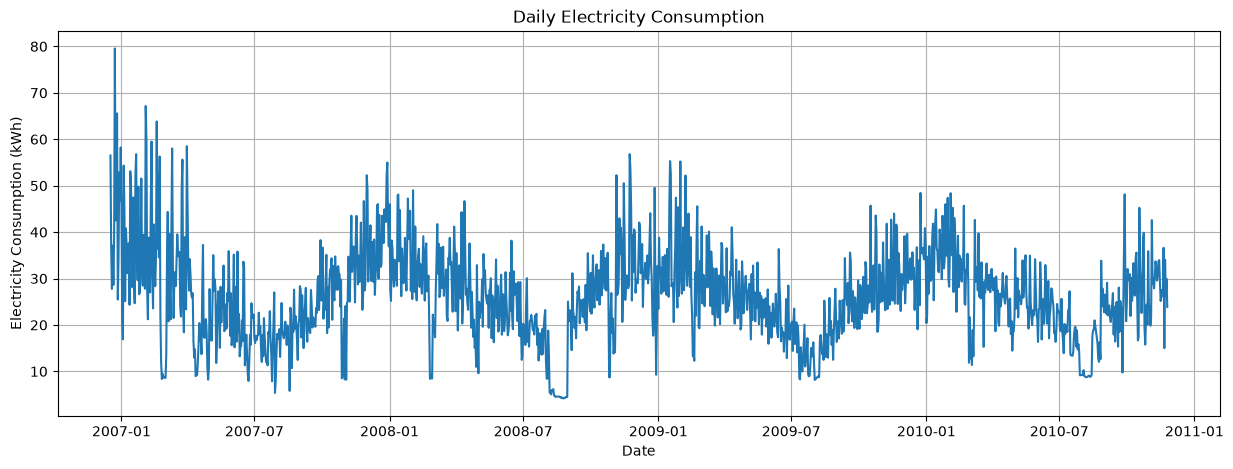

In [43]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_data.index,
    daily_data["Global_active_power"]
)

plt.title("Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Electricity Consumption (kWh)")
plt.grid(True)

plt.show()

### Exploratory Data Analysis (EDA)

### Check daily data quality
- verifying that our daily consumption calculations are reliable.
- A complete day should contain 1,440 minute-level readings.

In [44]:
# Count records available for each day
daily_counts = data.resample("D").size()

print("Minimum readings in a day:", daily_counts.min())
print("Maximum readings in a day:", daily_counts.max())
print("Days with fewer than 1440 readings:", (daily_counts < 1440).sum())
print("Complete days:", (daily_counts == 1440).sum())

Minimum readings in a day: 396
Maximum readings in a day: 1440
Days with fewer than 1440 readings: 2
Complete days: 1440


In [45]:
daily_data["Global_active_power"].describe()

count    1440.000000
mean       26.156425
std        10.036985
min         4.171633
25%        19.456383
50%        25.865617
75%        31.699783
max        79.556433
Name: Global_active_power, dtype: float64

### visualizing daily consumption

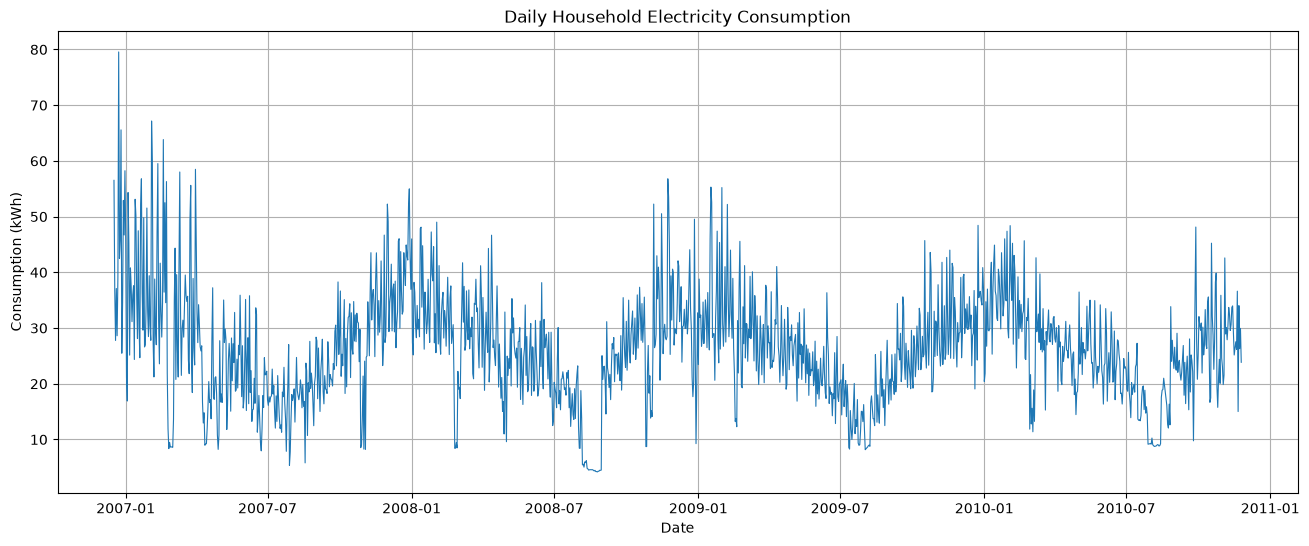

In [46]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_data.index,
    daily_data["Global_active_power"],
    linewidth=0.8
)

plt.title("Daily Household Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Consumption (kWh)")
plt.grid(True)
plt.show()

### Analyze consumption by day of the week

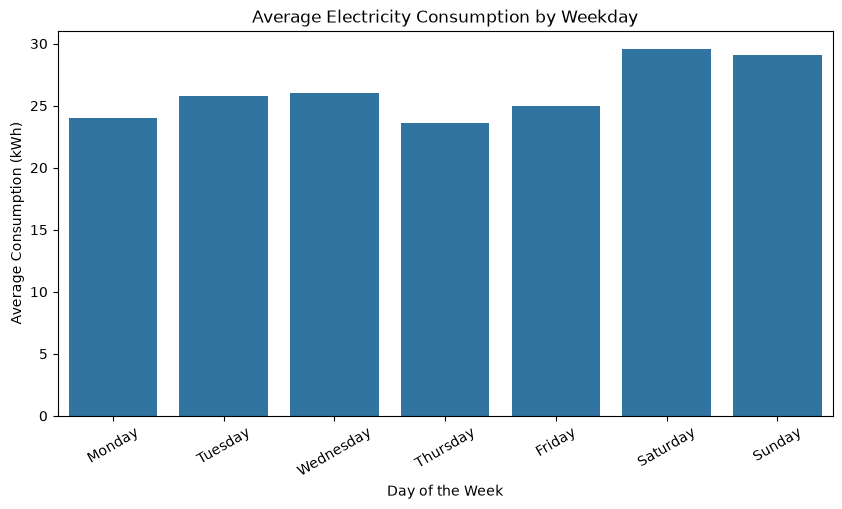

In [47]:
daily_data["day_name"] = daily_data.index.day_name()

weekly_consumption = daily_data.groupby("day_name")[
    "Global_active_power"
].mean()

# Arrange days in calendar order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly_consumption = weekly_consumption.reindex(day_order)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekly_consumption.index,
    y=weekly_consumption.values
)

plt.title("Average Electricity Consumption by Weekday")
plt.xlabel("Day of the Week")
plt.ylabel("Average Consumption (kWh)")
plt.xticks(rotation=30)
plt.show()

### Analyze monthly consumption

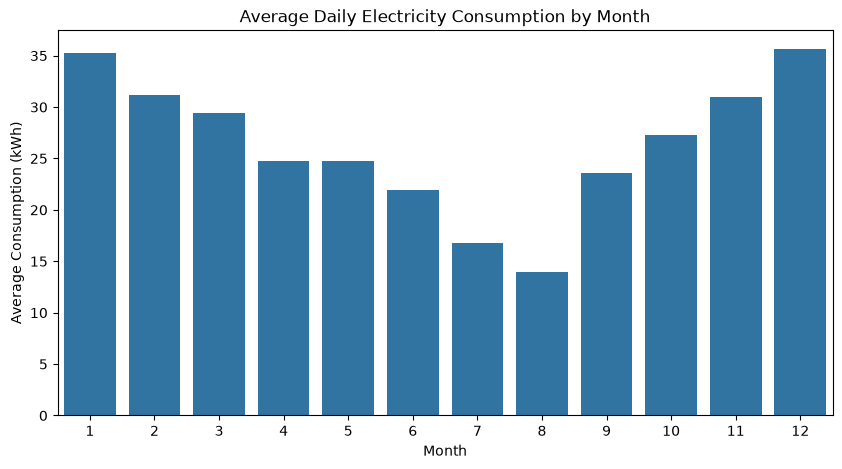

In [48]:
monthly_consumption = daily_data.groupby("month")[
    "Global_active_power"
].mean()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_consumption.index,
    y=monthly_consumption.values
)

plt.title("Average Daily Electricity Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Consumption (kWh)")
plt.show()

### Identify peak consumption days

In [49]:
top_consumption_days = daily_data.nlargest(
    10, "Global_active_power"
)

top_consumption_days[
    ["Global_active_power"]
]

,Global_active_power
datetime,
2006-12-23,79.556433
2007-02-03,67.162033
2006-12-26,65.568500
2007-02-18,63.829367
2007-02-04,59.932333
2007-02-11,59.520467
2007-03-31,58.491833
2006-12-31,58.236600
2007-03-11,58.010600
